# UTS Take Home – Analisis Goal Dataset

Isi notebook mengikuti soal:
* **a.** eksplorasi data (EDA) dan satu teknik inferensia (Kruskal-Wallis)
* **b.** kesimpulan
* **c.** visualisasi data yang relevan

Grafik disimpan di folder `grafik/`, angka penting di `hasil/hasil_analisis.json`.

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

FIG = Path('grafik'); FIG.mkdir(exist_ok=True)
OUT = Path('hasil'); OUT.mkdir(exist_ok=True)
R = {}

ACCENT, CTX, WARM, INK, MUTED = '#1F4E8C', '#A9B2BC', '#B85A0D', '#18222D', '#56626F'
plt.rcParams.update({'font.family': 'Segoe UI', 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': CTX, 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'figure.dpi': 110, 'savefig.dpi': 200})

def kom(x, d=2):
    return f'{x:.{d}f}'.replace('.', ',')

def judul(ax, teks, sub=None):
    ax.set_title(teks, loc='left', fontsize=13.5, fontweight='bold', color=INK, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=10, color=MUTED)

def judul_fig(fig, teks, sub=None):
    fig.text(0.01, 0.985, teks, fontsize=13.5, fontweight='bold', color=INK, va='top')
    if sub:
        fig.text(0.01, 0.985 - 0.30 / fig.get_figheight(), sub, fontsize=10, color=MUTED, va='top')

## a. Eksplorasi data

### Memuat dan memeriksa data

In [2]:
df = pd.read_csv('data/goal_dataset.csv', index_col=0)
print(df.shape)
print('nilai kosong:', int(df.isna().sum().sum()), '| id duplikat:', int(df.id.duplicated().sum()))
R['n_baris'], R['n_kolom'] = map(int, df.shape)
R['n_klub'] = int(df.team_title[~df.team_title.str.contains(',')].nunique())
df.head()

(522, 18)
nilai kosong: 0 | id duplikat: 0


,id,player_name,games,time,goals,xG,assists,xA,shots,key_passes,yellow_cards,red_cards,position,team_title,npg,npxG,xGChain,xGBuildup
0,647,Harry Kane,35,3097,23,22.174859,14,7.577094,138,49,1,0,F,Tottenham,19,19.130183,24.995648,4.451257
1,1250,Mohamed Salah,37,3085,22,20.250847,5,6.528526,126,55,0,0,F M S,Liverpool,16,15.683834,28.968234,9.800236
2,1228,Bruno Fernandes,37,3117,18,16.019454,12,11.474996,121,95,6,0,M S,Manchester United,9,8.407840,26.911412,11.932285
3,453,Son Heung-Min,37,3139,17,11.023287,10,9.512992,68,75,0,0,F M S,Tottenham,16,10.262118,20.671916,6.608751
4,822,Patrick Bamford,38,3085,17,18.401863,7,3.782247,107,30,3,0,F S,Leeds,15,16.879525,23.394953,4.131796


Kolom `position` berisi semua posisi yang pernah dimainkan (D = bek, F = penyerang, GK = kiper,
M = gelandang, S = cadangan). Setiap pemain dimasukkan ke peran paling menyerang yang pernah dimainkan.
Dibuat juga **gol per 90 menit** = gol ÷ menit × 90.

In [3]:
def kelompok(p):
    t = p.split()
    for kode, nama in (('F', 'Penyerang'), ('M', 'Gelandang'), ('D', 'Bek'), ('GK', 'Kiper')):
        if kode in t:
            return nama
    return 'Lainnya'

df['posisi'] = df.position.map(kelompok)
df['gol_per90'] = df.goals / df.time * 90
df['penalti'] = df.goals - df.npg
df.posisi.value_counts()

posisi
Gelandang    179
Bek          132
Penyerang    122
Lainnya       50
Kiper         39
Name: count, dtype: int64

### Statistik deskriptif

In [4]:
num = ['games','time','goals','xG','assists','xA','shots','key_passes','yellow_cards','red_cards']
desk = df[num].describe().T
R['total_gol'] = int(df.goals.sum()); R['total_xg'] = round(float(df.xG.sum()), 1)
R['total_penalti'] = int(df.penalti.sum()); R['total_tembakan'] = int(df.shots.sum())
R['konversi_tembakan'] = round(R['total_gol'] / R['total_tembakan'] * 100, 1)
R['pct_nol_gol'] = round(float((df.goals == 0).mean() * 100), 1)
R['mean_gol'] = round(float(df.goals.mean()), 2); R['skew_gol'] = round(float(df.goals.skew()), 2)
R['top10'] = df.nlargest(10, 'goals')[['player_name','team_title','goals','npg','penalti','xG']].round(2).to_dict('records')
desk.round(2)

,count,mean,std,min,25%,50%,75%,max
games,522.0,19.64,11.62,1.0,10.00,21.00,30.00,38.00
time,522.0,1420.07,1031.60,1.0,470.25,1342.00,2319.00,3420.00
goals,522.0,1.86,3.34,0.0,0.00,1.00,2.00,23.00
xG,522.0,2.00,3.32,0.0,0.07,0.74,2.05,22.17
assists,522.0,1.29,2.08,0.0,0.00,0.00,2.00,14.00
xA,522.0,1.38,1.89,0.0,0.05,0.69,2.05,11.47
shots,522.0,17.38,21.57,0.0,2.00,10.00,23.75,138.00
key_passes,522.0,12.96,16.16,0.0,1.00,7.00,19.00,95.00
yellow_cards,522.0,2.06,2.20,0.0,0.00,2.00,3.00,12.00
red_cards,522.0,0.09,0.30,0.0,0.00,0.00,0.00,2.00


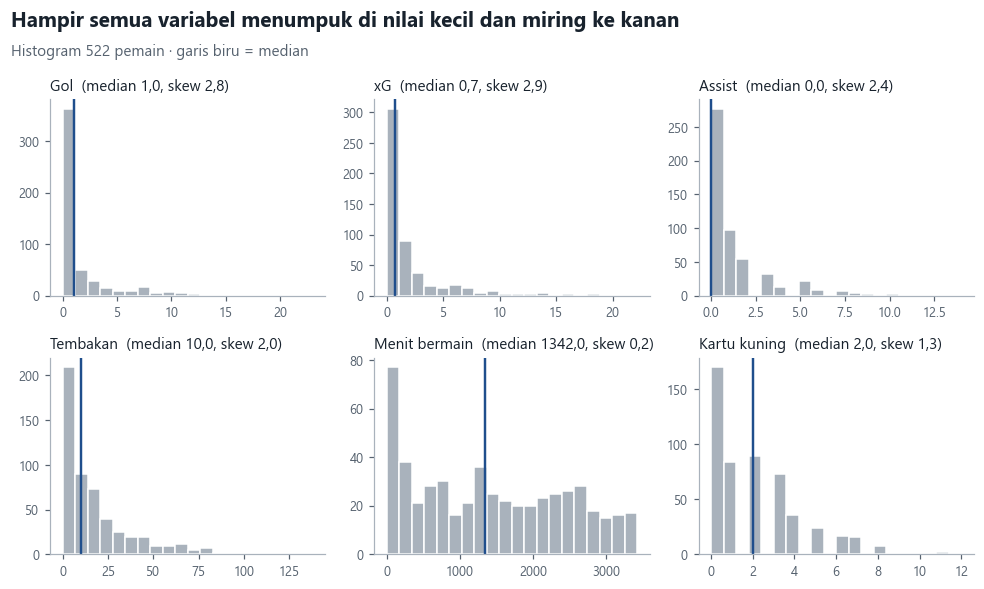

In [5]:
# EDA 1: sebaran variabel utama
cols = [('goals','Gol'), ('xG','xG'), ('assists','Assist'), ('shots','Tembakan'), ('time','Menit bermain'), ('yellow_cards','Kartu kuning')]
fig, axes = plt.subplots(2, 3, figsize=(9, 5.4))
for ax, (c, lab) in zip(axes.flat, cols):
    ax.hist(df[c], bins=20, color=CTX, edgecolor='white')
    ax.axvline(df[c].median(), color=ACCENT, lw=1.6)
    ax.set_title(f'{lab}  (median {kom(df[c].median(), 1)}, skew {kom(df[c].skew(), 1)})', fontsize=10, color=INK, loc='left')
    ax.tick_params(labelsize=8.5)
judul_fig(fig, 'Hampir semua variabel menumpuk di nilai kecil dan miring ke kanan',
          f'Histogram {R["n_baris"]} pemain · garis biru = median')
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(FIG / 'eda1_sebaran.png'); plt.show()

Histogram variabel utama: hampir semua variabel menumpuk di nilai kecil dan miring ke kanan (kecuali menit bermain). Ini tanda awal bahwa data tidak normal.

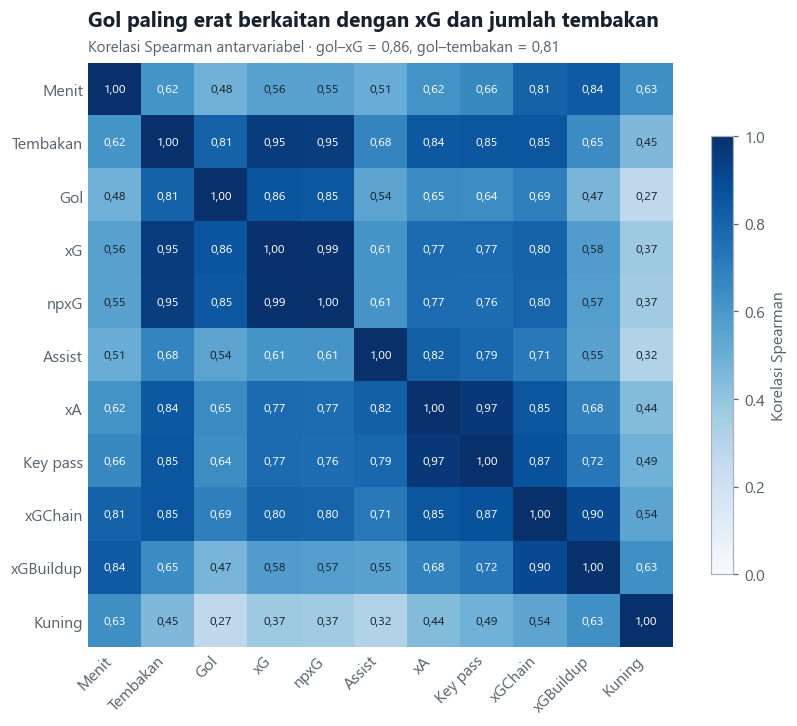

In [6]:
# EDA 2: korelasi Spearman antarvariabel
kor_cols = ['time','shots','goals','xG','npxG','assists','xA','key_passes','xGChain','xGBuildup','yellow_cards']
lab = ['Menit','Tembakan','Gol','xG','npxG','Assist','xA','Key pass','xGChain','xGBuildup','Kuning']
kor = df[kor_cols].corr(method='spearman')
R['kor_gol_xg'] = round(float(kor.loc['goals','xG']), 2); R['kor_gol_shots'] = round(float(kor.loc['goals','shots']), 2)
R['kor_gol_kuning'] = round(float(kor.loc['goals','yellow_cards']), 2)
fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(kor.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(lab)), lab, rotation=45, ha='right'); ax.set_yticks(range(len(lab)), lab)
for i in range(len(lab)):
    for j in range(len(lab)):
        v = kor.values[i, j]
        ax.text(j, i, kom(v, 2), ha='center', va='center', fontsize=8, color='white' if v > .6 else INK)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=.75, label='Korelasi Spearman')
judul(ax, 'Gol paling erat berkaitan dengan xG dan jumlah tembakan',
      f'Korelasi Spearman antarvariabel · gol–xG = {kom(R["kor_gol_xg"])}, gol–tembakan = {kom(R["kor_gol_shots"])}')
fig.tight_layout(); fig.savefig(FIG / 'eda2_korelasi.png'); plt.show()

Heatmap korelasi Spearman: gol paling erat berkaitan dengan xG dan jumlah tembakan, sedangkan hubungannya dengan kartu kuning lemah.

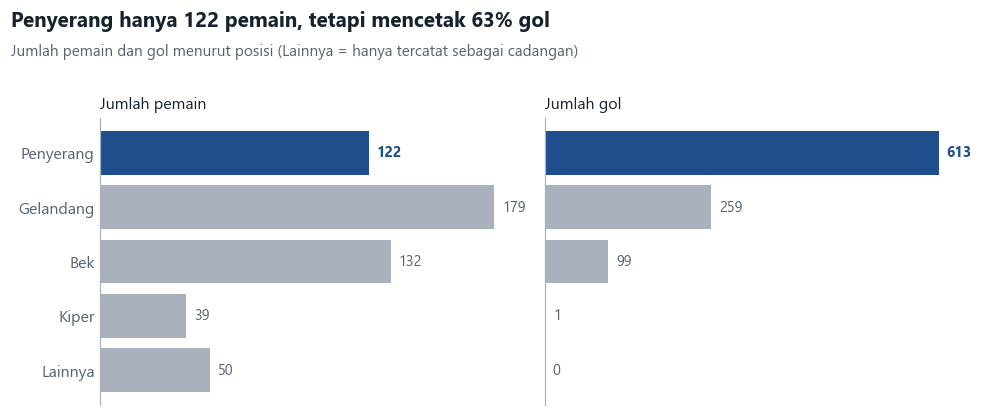

In [7]:
# EDA 3: pemain dan gol per posisi
urut = ['Penyerang','Gelandang','Bek','Kiper','Lainnya']
pos = df.groupby('posisi').agg(pemain=('id','count'), gol=('goals','sum')).loc[urut]
R['posisi_desk'] = pos.reset_index().to_dict('records')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, c, lab in zip(axes, ['pemain','gol'], ['Jumlah pemain','Jumlah gol']):
    ax.barh(pos.index, pos[c], color=[ACCENT if p == 'Penyerang' else CTX for p in pos.index])
    for y, v in enumerate(pos[c]):
        ax.text(v + pos[c].max() * .02, y, str(int(v)), va='center', fontsize=9.5,
                color=ACCENT if y == 0 else MUTED, fontweight='bold' if y == 0 else None)
    ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.tick_params(axis='y', length=0)
    ax.set_title(lab, loc='left', fontsize=10.5, color=INK)
axes[0].invert_yaxis()
pct = pos.loc['Penyerang','gol'] / pos.gol.sum() * 100
judul_fig(fig, f'Penyerang hanya {pos.loc["Penyerang","pemain"]} pemain, tetapi mencetak {kom(pct, 0)}% gol',
          'Jumlah pemain dan gol menurut posisi (Lainnya = hanya tercatat sebagai cadangan)')
fig.tight_layout(rect=(0, 0, 1, 0.82)); fig.savefig(FIG / 'eda3_posisi.png'); plt.show()

Jumlah pemain dan gol per posisi: penyerang paling sedikit pemainnya di antara pemain lapangan, tetapi menyumbang gol terbanyak. Pola inilah yang diuji secara statistik di bawah.

In [8]:
tim = df[~df.team_title.str.contains(',')].groupby('team_title').agg(gol=('goals','sum'), xg=('xG','sum')).sort_values('gol', ascending=False)
tim['selisih'] = tim.gol - tim.xg
R['klub'] = tim.round(1).reset_index().to_dict('records')
R['klub_di_bawah_xg'] = int((tim.selisih < 0).sum())
tim.head()

,gol,xg,selisih
team_title,,,
Manchester City,77,76.211204,0.788796
Manchester United,68,61.952792,6.047208
Tottenham,66,57.841412,8.158588
Leicester,64,59.098597,4.901403
Liverpool,64,72.069302,-8.069302


## a. Analisis inferensia: uji Kruskal-Wallis

**Pertanyaan:** apakah produktivitas gol per 90 menit berbeda antara penyerang, gelandang, dan bek?

**Persiapan data.** Produktivitas diukur dengan gol per 90 menit = gol ÷ menit bermain × 90.
*Alasan:* menit bermain setiap pemain berbeda, sehingga tanpa disamakan pemain yang sering bermain otomatis terlihat lebih produktif.
Hanya pemain dengan minimal 900 menit (setara 10 laga penuh) yang dipakai.
*Alasan:* pemain yang bermain sebentar menghasilkan angka yang tidak stabil; misalnya bermain 10 menit lalu mencetak 1 gol sama dengan 9 gol per 90 menit.
Kiper tidak diikutkan karena tidak bertugas mencetak gol.

* H0: distribusi gol per 90 menit sama di ketiga posisi
* H1: minimal satu posisi berbeda
* α = 0,05

### Cek asumsi ANOVA: normalitas dan homogenitas varians

ANOVA hanya bisa dipakai jika data di setiap kelompok menyebar normal (dicek dengan **Shapiro-Wilk**)
dan memiliki sebaran yang mirip (dicek dengan **Levene**). Jika p < 0,05, syarat tersebut tidak terpenuhi.

In [9]:
grup = ['Penyerang','Gelandang','Bek']
kw = df[(df.time >= 900) & df.posisi.isin(grup)].copy()
R['kw_n'] = int(len(kw))
data = {g: kw.loc[kw.posisi == g, 'gol_per90'] for g in grup}
R['shapiro'] = {g: {'W': round(float(stats.shapiro(d).statistic), 3), 'p': float(stats.shapiro(d).pvalue)} for g, d in data.items()}
lev = stats.levene(*data.values())
R['levene'] = {'stat': round(float(lev.statistic), 2), 'p': float(lev.pvalue)}
print(R['shapiro']); print(R['levene'])

{'Penyerang': {'W': 0.942, 'p': 0.00038081079782204387}, 'Gelandang': {'W': 0.595, 'p': 2.3695585906999468e-17}, 'Bek': {'W': 0.872, 'p': 9.735203305506084e-07}}
{'stat': 26.85, 'p': 1.8576126810805844e-11}


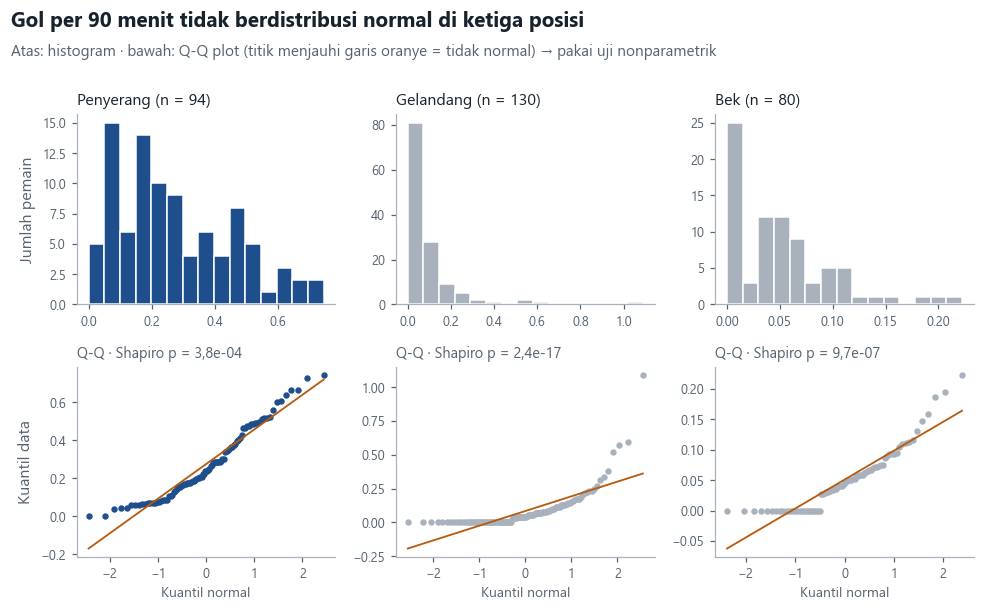

In [10]:
# INF 1: histogram dan Q-Q plot per posisi
fig, axes = plt.subplots(2, 3, figsize=(9, 5.6))
for k, g in enumerate(grup):
    d = data[g]
    axes[0, k].hist(d, bins=15, color=ACCENT if g == 'Penyerang' else CTX, edgecolor='white')
    axes[0, k].set_title(f'{g} (n = {len(d)})', loc='left', fontsize=10.5, color=INK)
    axes[0, k].tick_params(labelsize=8.5)
    (osm, osr), (sl, ic, _) = stats.probplot(d, dist='norm')
    axes[1, k].scatter(osm, osr, s=10, color=ACCENT if g == 'Penyerang' else CTX)
    axes[1, k].plot(osm, sl * osm + ic, color=WARM, lw=1.2)
    axes[1, k].set_title(f'Q-Q · Shapiro p = {R["shapiro"][g]["p"]:.1e}'.replace('.', ','), loc='left', fontsize=9.5, color=MUTED)
    axes[1, k].tick_params(labelsize=8.5)
axes[0, 0].set_ylabel('Jumlah pemain'); axes[1, 0].set_ylabel('Kuantil data')
for a in axes[1]: a.set_xlabel('Kuantil normal', fontsize=9)
judul_fig(fig, 'Gol per 90 menit tidak berdistribusi normal di ketiga posisi',
          'Atas: histogram · bawah: Q-Q plot (titik menjauhi garis oranye = tidak normal) → pakai uji nonparametrik')
fig.tight_layout(rect=(0, 0, 1, 0.88)); fig.savefig(FIG / 'inf1_normalitas.png'); plt.show()

Histogram dan Q-Q plot tiap posisi: titik-titik menjauhi garis oranye, jadi data tidak normal dan uji nonparametrik lebih tepat.

**Kenapa Kruskal-Wallis, bukan ANOVA:** hasil uji Shapiro-Wilk menunjukkan bahwa data gol per 90 menit tidak menyebar normal
pada ketiga posisi (p < 0,001). Uji Levene juga menunjukkan bahwa lebar sebaran data antarposisi berbeda (p < 0,001).
Karena kedua syarat ANOVA tidak terpenuhi, digunakan uji Kruskal-Wallis. Uji ini tidak membandingkan nilai aslinya,
melainkan urutan (peringkat) data, sehingga tetap dapat dipakai walaupun data tidak normal dan memiliki nilai yang ekstrem.

### Hasil uji Kruskal-Wallis

In [11]:
H, p = stats.kruskal(*data.values())
n = len(kw)
R['kw'] = {'H': round(float(H), 2), 'df': len(grup) - 1, 'p': float(p), 'epsilon2': round(float(H / (n - 1)), 3)}
ring = kw.groupby('posisi').gol_per90.agg(['count','median','mean']).loc[grup]
ring['mean_rank'] = kw.gol_per90.rank().groupby(kw.posisi).mean().loc[grup]
R['kw_ringkas'] = ring.round(3).reset_index().rename(columns={'count': 'n'}).to_dict('records')
print(R['kw']); ring.round(3)

{'H': 110.24, 'df': 2, 'p': 1.1499870458464407e-24, 'epsilon2': 0.364}


,count,median,mean,mean_rank
posisi,,,,
Penyerang,94,0.239,0.276,230.660
Gelandang,130,0.042,0.084,121.946
Bek,80,0.045,0.051,110.312


### Cara memperoleh H, p, dan ε² (dihitung manual)

Seluruh pemain diurutkan berdasarkan gol per 90 menit dan diberi peringkat 1–N, lalu rata-rata peringkat tiap posisi
dibandingkan. Jika posisi tidak berpengaruh, rata-rata peringkat tiap posisi seharusnya mendekati titik tengah (N + 1) / 2.
Selisih itu dirangkum dengan rumus:

$$H = \frac{12}{N(N+1)} \sum \frac{R_i^2}{n_i} - 3(N+1)$$

dengan N = jumlah seluruh pemain, nᵢ = jumlah pemain tiap posisi, dan Rᵢ = jumlah peringkat tiap posisi.

* **Koreksi nilai kembar.** *Alasan:* banyak pemain bernilai sama persis (0 gol); tanpa koreksi, nilai H sedikit terlalu kecil.
* **Derajat bebas = jumlah kelompok − 1.** H dibandingkan dengan distribusi chi-square untuk memperoleh p-value.
* **Effect size ε² = H / (N − 1).** *Alasan:* nilai p hanya menunjukkan bahwa perbedaan itu nyata, bukan seberapa besar.
  ε² bernilai 0 sampai 1 dan menunjukkan berapa bagian perbedaan peringkat yang dijelaskan oleh posisi.

In [12]:
N = len(kw)
kw['peringkat'] = kw.gol_per90.rank()
tab = kw.groupby('posisi').peringkat.agg(n='count', R='sum', rata_peringkat='mean').loc[grup]
print('titik tengah peringkat =', (N + 1) / 2)
display(tab.round(1))

H_awal = 12 / (N * (N + 1)) * (tab.R**2 / tab.n).sum() - 3 * (N + 1)
t = kw.gol_per90.value_counts()
C = 1 - (t**3 - t).sum() / (N**3 - N)
H_koreksi = H_awal / C
dfree = len(grup) - 1
kritis = stats.chi2.ppf(0.95, dfree)
p_manual = stats.chi2.sf(H_koreksi, dfree)
eps2 = H_koreksi / (N - 1)
print(f'H tanpa koreksi       = {H_awal:.2f}')
print(f'nilai kembar terbanyak = {t.iloc[0]} pemain bernilai {t.index[0]:.0f}; faktor koreksi C = {C:.4f}')
print(f'H terkoreksi          = {H_awal:.2f} / {C:.4f} = {H_koreksi:.2f}')
print(f'derajat bebas         = {len(grup)} - 1 = {dfree}; batas kritis chi-square (α = 0,05) = {kritis:.2f}')
print(f'p-value               = {p_manual:.2e}  ->  H0 {"ditolak" if p_manual < 0.05 else "diterima"}')
print(f'epsilon kuadrat       = {H_koreksi:.2f} / {N - 1} = {eps2:.3f}')
assert abs(H_koreksi - R['kw']['H']) < 0.01   # sama dengan hasil scipy

titik tengah peringkat = 152.5


,n,R,rata_peringkat
posisi,,,
Penyerang,94,21682.0,230.7
Gelandang,130,15853.0,121.9
Bek,80,8825.0,110.3


H tanpa koreksi       = 108.45
nilai kembar terbanyak = 77 pemain bernilai 0; faktor koreksi C = 0.9838
H terkoreksi          = 108.45 / 0.9838 = 110.24
derajat bebas         = 3 - 1 = 2; batas kritis chi-square (α = 0,05) = 5.99
p-value               = 1.15e-24  ->  H0 ditolak
epsilon kuadrat       = 110.24 / 303 = 0.364


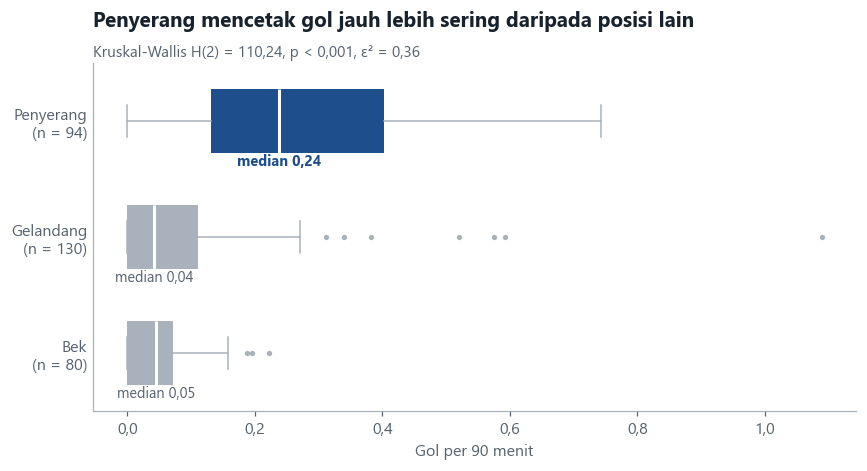

In [13]:
# INF 2: boxplot gol per 90 menit per posisi
fig, ax = plt.subplots(figsize=(8, 4.4))
bp = ax.boxplot(list(data.values()), vert=False, patch_artist=True, widths=.55,
                medianprops={'color': 'white', 'linewidth': 2},
                flierprops={'marker': 'o', 'markersize': 3.5, 'markerfacecolor': CTX, 'markeredgecolor': 'none'})
for patch, g in zip(bp['boxes'], grup):
    patch.set_facecolor(ACCENT if g == 'Penyerang' else CTX); patch.set_edgecolor('none')
for el in ('whiskers', 'caps'):
    for line in bp[el]: line.set_color(CTX)
ax.set_yticks([1, 2, 3], [f'{g}\n(n = {len(d)})' for g, d in data.items()]); ax.tick_params(axis='y', length=0)
for i, d in enumerate(data.values(), 1):
    ax.text(d.median(), i + .38, f'median {kom(d.median())}', ha='center', fontsize=9.5,
            color=ACCENT if i == 1 else MUTED, fontweight='bold' if i == 1 else None)
ax.invert_yaxis(); ax.set_xlabel('Gol per 90 menit')
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: kom(v, 1)))
judul(ax, 'Penyerang mencetak gol jauh lebih sering daripada posisi lain',
      f'Kruskal-Wallis H({R["kw"]["df"]}) = {kom(R["kw"]["H"])}, p < 0,001, ε² = {kom(R["kw"]["epsilon2"])}')
fig.tight_layout(); fig.savefig(FIG / 'inf2_boxplot.png'); plt.show()

### Uji lanjut Dunn (koreksi Bonferroni): posisi mana yang berbeda?

*Alasan:* Kruskal-Wallis hanya menyatakan bahwa ada perbedaan, tetapi tidak menyebut posisi mana yang berbeda.
Uji Dunn membandingkan setiap pasangan posisi. Karena ada 3 pasangan yang diuji sekaligus, peluang "salah menemukan"
perbedaan ikut naik, sehingga nilai p setiap pasangan dikalikan 3 (koreksi Bonferroni) agar kesimpulannya tetap adil.

In [14]:
def dunn(d, val, by, groups):
    rk = d[val].rank(); N = len(d)
    ties = d[val].value_counts(); tie = (ties**3 - ties).sum() / (12 * (N - 1))
    mr = rk.groupby(d[by]).mean(); nn = d.groupby(by).size()
    m = len(groups) * (len(groups) - 1) // 2
    hasil = []
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            a, b = groups[i], groups[j]
            se = math.sqrt((N * (N + 1) / 12 - tie) * (1 / nn[a] + 1 / nn[b]))
            z = (mr[a] - mr[b]) / se
            pv = 2 * (1 - stats.norm.cdf(abs(z)))
            hasil.append({'a': a, 'b': b, 'pasangan': f'{a} vs {b}', 'z': round(float(z), 2), 'p_bonferroni': float(min(1, pv * m))})
    return pd.DataFrame(hasil)

dn = dunn(kw, 'gol_per90', 'posisi', grup)
R['dunn'] = dn.drop(columns=['a','b']).to_dict('records')
dn

,a,b,pasangan,z,p_bonferroni
0,Penyerang,Gelandang,Penyerang vs Gelandang,9.21,0.0
1,Penyerang,Bek,Penyerang vs Bek,9.07,0.0
2,Gelandang,Bek,Gelandang vs Bek,0.94,1.0


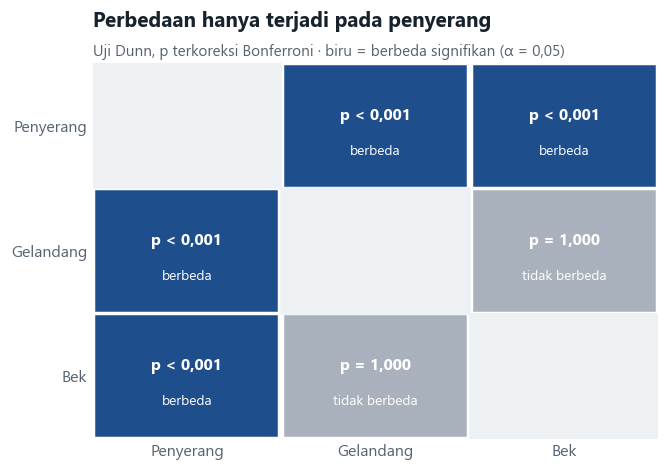

In [15]:
# INF 3: matriks p-value Dunn
mat = pd.DataFrame(np.nan, index=grup, columns=grup)
for _, r in dn.iterrows():
    mat.loc[r.a, r.b] = mat.loc[r.b, r.a] = r.p_bonferroni
fig, ax = plt.subplots(figsize=(6.2, 4.4))
for i, a in enumerate(grup):
    for j, b in enumerate(grup):
        if i == j:
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color='#EEF1F4')); continue
        pv = mat.loc[a, b]; sig = pv < .05
        ax.add_patch(plt.Rectangle((j - .48, i - .48), .96, .96, color=ACCENT if sig else CTX))
        ax.text(j, i - .08, 'p < 0,001' if pv < .001 else f'p = {kom(pv, 3)}', ha='center', va='center', color='white', fontsize=10.5, fontweight='bold')
        ax.text(j, i + .2, 'berbeda' if sig else 'tidak berbeda', ha='center', va='center', color='white', fontsize=9)
ax.set_xlim(-.5, 2.5); ax.set_ylim(2.5, -.5)
ax.set_xticks(range(3), grup); ax.set_yticks(range(3), grup)
ax.spines[:].set_visible(False); ax.tick_params(length=0)
judul(ax, 'Perbedaan hanya terjadi pada penyerang', 'Uji Dunn, p terkoreksi Bonferroni · biru = berbeda signifikan (α = 0,05)')
fig.tight_layout(); fig.savefig(FIG / 'inf3_dunn.png'); plt.show()

**Hasil:** H0 ditolak. Gol per 90 menit berbeda signifikan antarposisi dengan efek cukup besar.
Uji Dunn menunjukkan penyerang berbeda dari gelandang dan bek, sedangkan gelandang dan bek tidak berbeda.

### Ringkasan alasan setiap perhitungan

| Perhitungan | Kenapa dipakai |
|---|---|
| Gol per 90 menit | Menit bermain pemain berbeda-beda; tanpa disamakan, pemain yang sering bermain otomatis terlihat lebih produktif. |
| Minimal 900 menit | Pemain yang bermain sebentar menghasilkan angka yang tidak stabil. |
| Uji Shapiro-Wilk | Mengecek apakah data menyebar normal, syarat pertama ANOVA. |
| Uji Levene | Mengecek apakah lebar sebaran data tiap posisi mirip, syarat kedua ANOVA. |
| Uji Kruskal-Wallis | Kedua syarat ANOVA tidak terpenuhi, jadi dipakai uji yang memakai peringkat. |
| Koreksi nilai kembar | Banyak pemain bernilai 0 gol; tanpa koreksi, nilai H sedikit terlalu kecil. |
| Effect size ε² | Nilai p hanya menunjukkan ada perbedaan; ε² menunjukkan seberapa besar perbedaannya. |
| Uji Dunn | Kruskal-Wallis tidak menyebut posisi mana yang berbeda; Dunn membandingkan setiap pasangan. |
| Koreksi Bonferroni | Menguji 3 pasangan sekaligus menaikkan peluang salah menemukan perbedaan, jadi nilai p dikalikan 3. |

## b. Kesimpulan

Data musim ini menunjukkan bahwa gol hanya dicetak oleh sebagian kecil pemain. Hampir separuh pemain (48,9%) tidak mencetak
gol sama sekali, sementara Harry Kane memimpin dengan 23 gol disusul Mohamed Salah dengan 22 gol. Mencetak gol juga tidak mudah:
dari 9.072 tembakan, hanya 10,7% yang berbuah gol, dan sekitar satu dari sepuluh gol berasal dari penalti. Di level klub,
Manchester City menjadi tim paling produktif dengan 77 gol, sedangkan Sheffield United hanya 18 gol.

Uji Kruskal-Wallis membuktikan bahwa posisi berpengaruh besar terhadap produktivitas gol. Gol per 90 menit berbeda signifikan
antarposisi (H = 110,24, p < 0,001), dan uji Dunn menunjukkan bahwa perbedaannya berasal dari penyerang. Median penyerang
0,24 gol per 90 menit, kira-kira satu gol setiap empat laga penuh, sekitar lima kali lipat gelandang (0,04) dan bek (0,05).
Gelandang dan bek sendiri tidak berbeda signifikan, walaupun ada beberapa gelandang serang yang produktivitasnya setara penyerang.

Selain posisi, kualitas peluang juga menentukan. Jumlah gol pemain sangat sejalan dengan xG-nya, tetapi secara total gol yang
tercipta (972) lebih sedikit daripada xG (1044,4), dan 13 dari 20 klub mencetak gol di bawah peluang yang mereka ciptakan.
Jadi, bagi klub, menilai pemain sebaiknya tidak hanya dari jumlah gol, tetapi juga dari posisi, menit bermain, dan xG, supaya
tidak tertipu oleh pemain yang sedang beruntung atau kurang beruntung. Keterbatasan analisis ini adalah datanya hanya satu liga
dan satu musim, sehingga hasilnya belum tentu berlaku untuk liga lain.

## c. Visualisasi

Grafik di bagian ini adalah grafik penjelas (untuk audiens), berbeda dari grafik eksplorasi di bagian a. Grafik dibuat dengan
prinsip *storytelling with data*: judul langsung berisi pesan, satu warna biru untuk data yang disorot, abu-abu untuk konteks,
dan tanpa elemen yang tidak perlu.

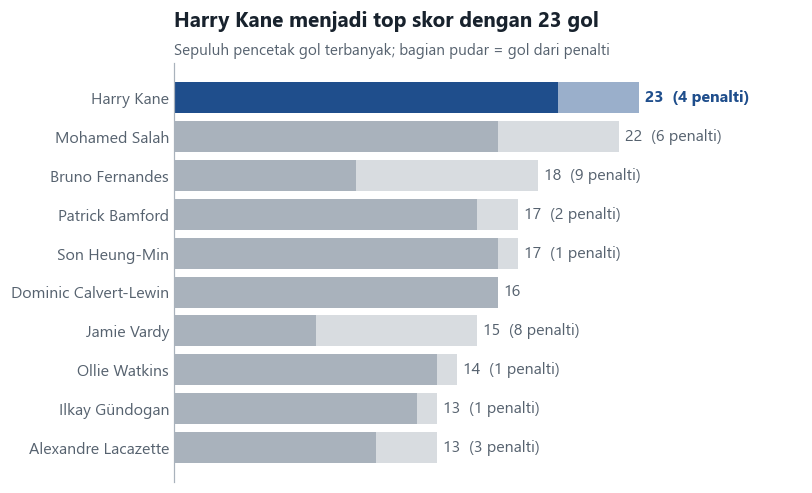

In [16]:
# C1: top 10 pencetak gol
top = df.nlargest(10, 'goals').sort_values('goals')
fig, ax = plt.subplots(figsize=(7.5, 4.6))
cl = [ACCENT if i == len(top) - 1 else CTX for i in range(len(top))]
ax.barh(top.player_name, top.npg, color=cl); ax.barh(top.player_name, top.penalti, left=top.npg, color=cl, alpha=.45)
for y, (g, pen) in enumerate(zip(top.goals, top.penalti)):
    ax.text(g + .3, y, f'{g}' + (f'  ({pen} penalti)' if pen else ''), va='center',
            color=ACCENT if y == len(top) - 1 else MUTED, fontweight='bold' if y == len(top) - 1 else None)
ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.tick_params(axis='y', length=0); ax.set_xlim(0, top.goals.max() * 1.35)
judul(ax, f'{top.player_name.iloc[-1]} menjadi top skor dengan {top.goals.iloc[-1]} gol', 'Sepuluh pencetak gol terbanyak; bagian pudar = gol dari penalti')
fig.tight_layout(); fig.savefig(FIG / 'c1_top_skor.png'); plt.show()

Bar horizontal dipakai karena membandingkan kategori (pemain) dengan nama yang panjang. Bagian pudar menunjukkan gol penalti.

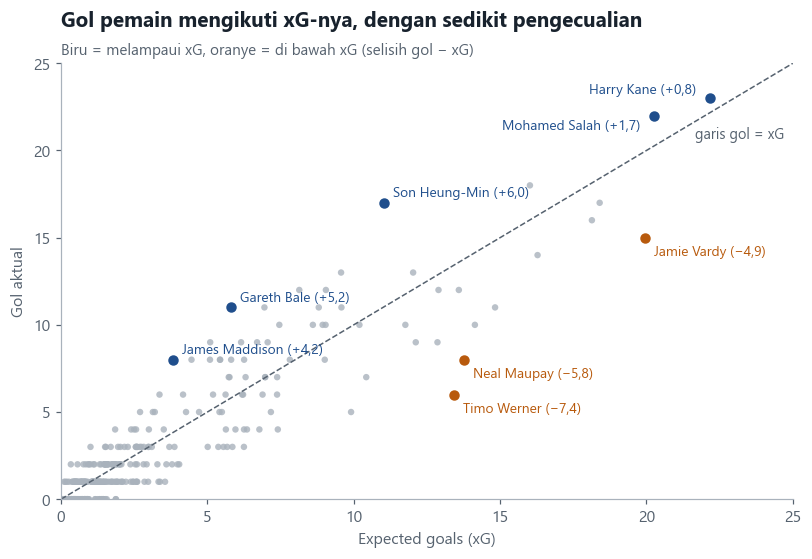

In [17]:
# C2: xG vs gol aktual (pemain >= 900 menit)
q = df[df.time >= 900].copy(); q['selisih'] = q.goals - q.xG
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(q.xG, q.goals, s=18, color=CTX, alpha=.8, edgecolor='none')
lim = max(q.xG.max(), q.goals.max()) + 2
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls='--'); ax.text(lim - .3, lim - 4.3, 'garis gol = xG', color=MUTED, ha='right', fontsize=9.5)
lab = pd.concat([q.nlargest(3, 'selisih'), q.nsmallest(3, 'selisih'), q.nlargest(2, 'goals')]).drop_duplicates('id')
for _, r in lab.iterrows():
    c = ACCENT if r.selisih > 0 else WARM; kiri = r.goals >= 20
    ax.scatter(r.xG, r.goals, s=34, color=c, zorder=3)
    ax.annotate(f'{r.player_name} ({"+" if r.selisih > 0 else "−"}{kom(abs(r.selisih), 1)})', (r.xG, r.goals),
                xytext=(-9, 3 if r.goals > 22 else -9) if kiri else (6, 4 if r.selisih > 0 else -12),
                textcoords='offset points', fontsize=9, color=c, ha='right' if kiri else 'left')
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_xlabel('Expected goals (xG)'); ax.set_ylabel('Gol aktual')
judul(ax, 'Gol pemain mengikuti xG-nya, dengan sedikit pengecualian', 'Biru = melampaui xG, oranye = di bawah xG (selisih gol − xG)')
fig.tight_layout(); fig.savefig(FIG / 'c2_xg_vs_gol.png'); plt.show()

Scatterplot untuk hubungan dua variabel kontinu. Titik di atas garis putus-putus berarti pemain mencetak gol lebih banyak dari xG-nya.

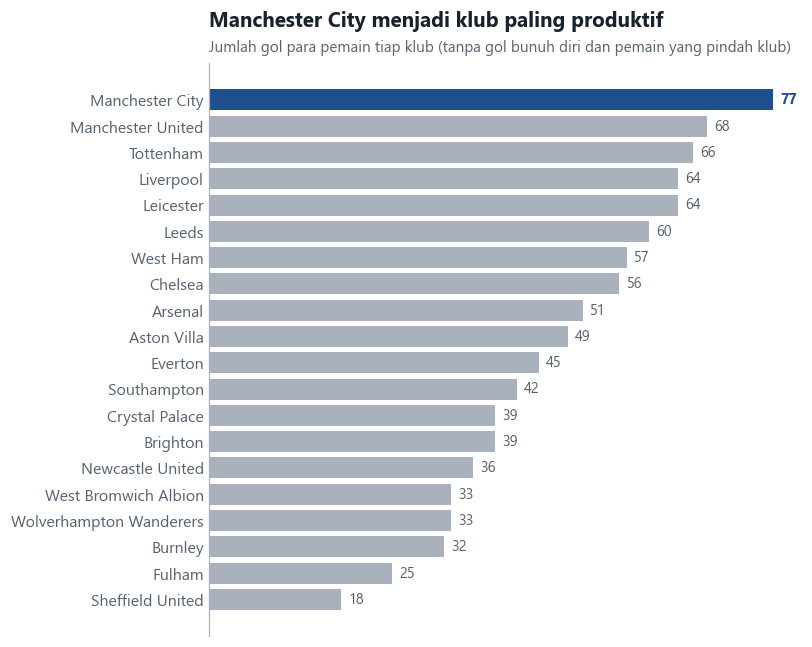

In [18]:
# C3: gol per klub
tk = tim.sort_values('gol')
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(tk.index, tk.gol, color=[ACCENT if i == len(tk) - 1 else CTX for i in range(len(tk))])
for y, g in enumerate(tk.gol):
    ax.text(g + 1, y, str(int(g)), va='center', fontsize=9.5, color=ACCENT if y == len(tk) - 1 else MUTED,
            fontweight='bold' if y == len(tk) - 1 else None)
ax.set_xticks([]); ax.spines['bottom'].set_visible(False); ax.tick_params(axis='y', length=0)
judul(ax, f'{tk.index[-1]} menjadi klub paling produktif', 'Jumlah gol para pemain tiap klub (tanpa gol bunuh diri dan pemain yang pindah klub)')
fig.tight_layout(); fig.savefig(FIG / 'c3_gol_per_klub.png'); plt.show()

Bar terurut supaya peringkat klub langsung terbaca; hanya klub teratas yang diberi warna.

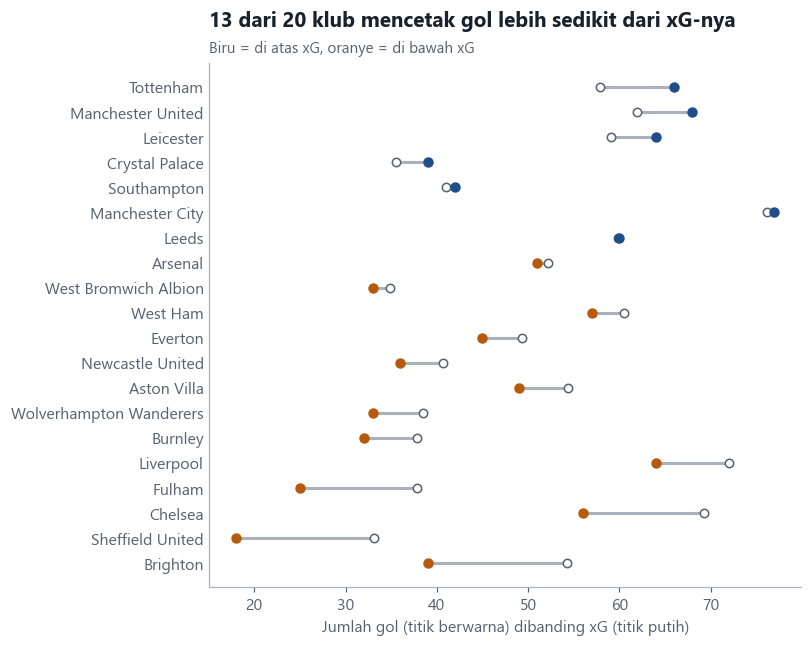

In [19]:
# C4: gol vs xG per klub
ts = tim.sort_values('selisih')
fig, ax = plt.subplots(figsize=(7.5, 6))
for y, (k, r) in enumerate(ts.iterrows()):
    c = ACCENT if r.selisih > 0 else WARM
    ax.plot([r.xg, r.gol], [y, y], color=CTX, lw=2, zorder=1)
    ax.scatter(r.xg, y, color='white', edgecolor=MUTED, s=30, zorder=2); ax.scatter(r.gol, y, color=c, s=34, zorder=3)
ax.set_yticks(range(len(ts)), ts.index); ax.tick_params(axis='y', length=0)
ax.set_xlabel('Jumlah gol (titik berwarna) dibanding xG (titik putih)')
judul(ax, f'{R["klub_di_bawah_xg"]} dari {len(ts)} klub mencetak gol lebih sedikit dari xG-nya', 'Biru = di atas xG, oranye = di bawah xG')
fig.tight_layout(); fig.savefig(FIG / 'c4_gol_vs_xg_klub.png'); plt.show()

Dumbbell chart memperlihatkan selisih gol dan xG tiap klub; oranye berarti klub mencetak gol di bawah peluangnya.

In [20]:
json.dump(R, open(OUT / 'hasil_analisis.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=float)
print('selesai')

selesai
